# 02 · Phase 1 results: tabular models for next-day fire prediction

Run order: `python -m src.aml.train --protocol spatial --ablation`, `python -m src.aml.train --protocol official`,
`python -m src.aml.evaluate`. This notebook reads the saved results; it does not retrain.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
R = os.path.abspath('../experiments/ndws/results')
def table(protocol):
    df = pd.read_csv(f'{R}/{protocol}/metrics_table.csv').set_index('model')
    return df[['pr_auc','pr_auc_ci_low','pr_auc_ci_high','roc_auc','f1','precision','recall',
               'recall_at_1pct_fpr','recall_at_5pct_fpr','brier','val_pr_auc']]

## 1. Main results: spatially disjoint test split
Thresholds for F1/precision/recall were chosen on validation. PR-AUC CIs come from a patch-level bootstrap.

In [2]:
table('spatial')

,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,f1,precision,recall,recall_at_1pct_fpr,recall_at_5pct_fpr,brier,val_pr_auc
model,,,,,,,,,,,
persistence,0.0368,0.0320,0.0411,0.5716,0.1766,0.2244,0.1456,0.1521,0.1863,0.0066,0.0701
neighbourhood_persist,0.0637,0.0555,0.0714,0.6414,0.2028,0.1810,0.2305,0.2916,0.3202,0.0053,0.1175
logistic_regression,0.1169,0.1063,0.1272,0.8673,0.2256,0.1926,0.2724,0.3740,0.6390,0.0045,0.1877
random_forest,0.1354,0.1233,0.1486,0.8852,0.2344,0.1907,0.3041,0.3816,0.6273,0.0044,0.2280
xgboost,0.1406,0.1281,0.1541,0.8987,0.2456,0.2303,0.2630,0.3823,0.6278,0.0044,0.2304
lightgbm,0.1381,0.1267,0.1500,0.8963,0.2440,0.2288,0.2612,0.3818,0.6212,0.0044,0.2297


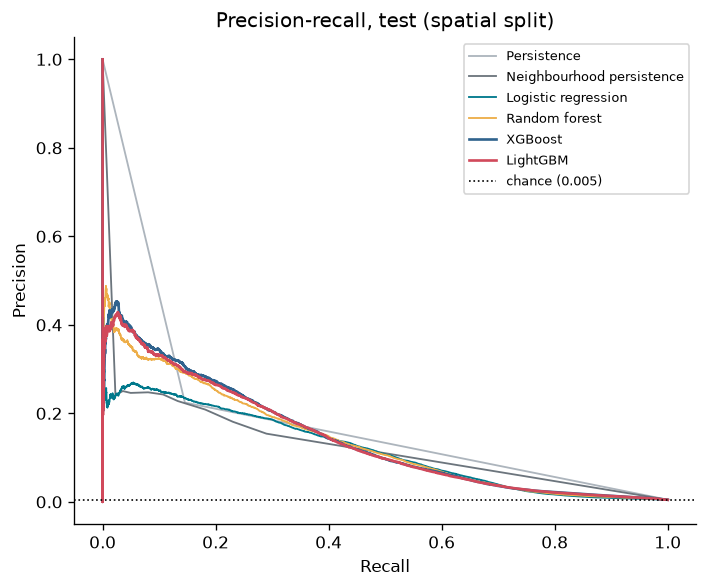

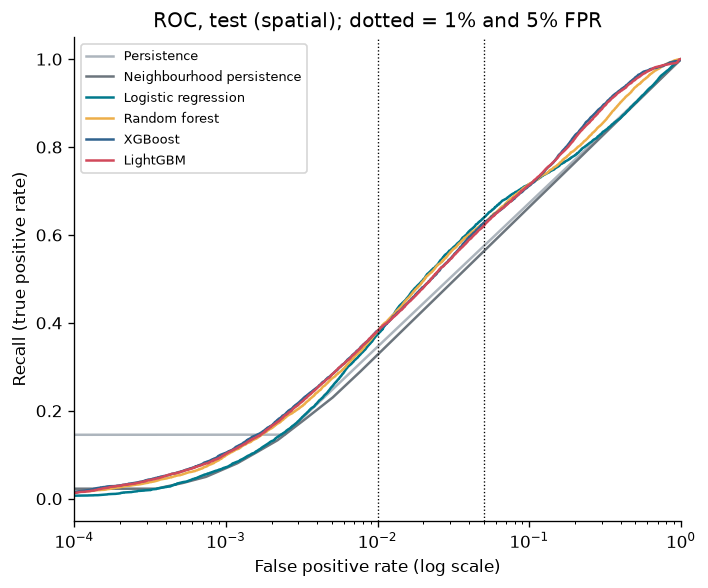

In [3]:
display(Image(f'{R}/spatial/pr_curves.png')); display(Image(f'{R}/spatial/roc_curves.png'))

## 2. Is the best model significantly better? (paired patch bootstrap on ΔPR-AUC)

In [4]:
pd.DataFrame(json.load(open(f'{R}/spatial/significance.json'))).T

,delta,ci_low,ci_high,p_le_zero
lightgbm - logistic_regression,0.0212,0.0159,0.0264,0.0000
lightgbm - random_forest,0.0027,-0.0019,0.0064,0.0940
lightgbm - xgboost,-0.0024,-0.0067,0.0010,0.8960
lightgbm - persistence,0.1013,0.0927,0.1104,0.0000
xgboost - logistic_regression,0.0236,0.0182,0.0298,0.0000
logistic_regression - persistence,0.0801,0.0720,0.0881,0.0000


## 3. Official NDWS split (comparable with Huot et al., 2022: LR 19.8, RF 22.5, CNN 28.4, persistence 11.5 PR-AUC %)

In [5]:
table('official')

,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,f1,precision,recall,recall_at_1pct_fpr,recall_at_5pct_fpr,brier,val_pr_auc
model,,,,,,,,,,,
persistence,0.1065,0.0969,0.1177,0.6333,0.3093,0.3572,0.2728,0.2755,0.3048,0.0153,0.0597
neighbourhood_persist,0.1734,0.1571,0.1912,0.7290,0.3372,0.2880,0.4066,0.3601,0.4905,0.0121,0.0945
logistic_regression,0.2302,0.2130,0.2490,0.9029,0.3269,0.2459,0.4875,0.3632,0.6654,0.0106,0.1582
random_forest,0.2650,0.2475,0.2824,0.9010,0.3426,0.2610,0.4985,0.3885,0.6793,0.0104,0.2053
xgboost,0.2650,0.2483,0.2827,0.9107,0.3319,0.2419,0.5285,0.3888,0.6803,0.0104,0.2064
lightgbm,0.2626,0.2457,0.2806,0.9053,0.3343,0.2453,0.5246,0.3875,0.6798,0.0104,0.2039


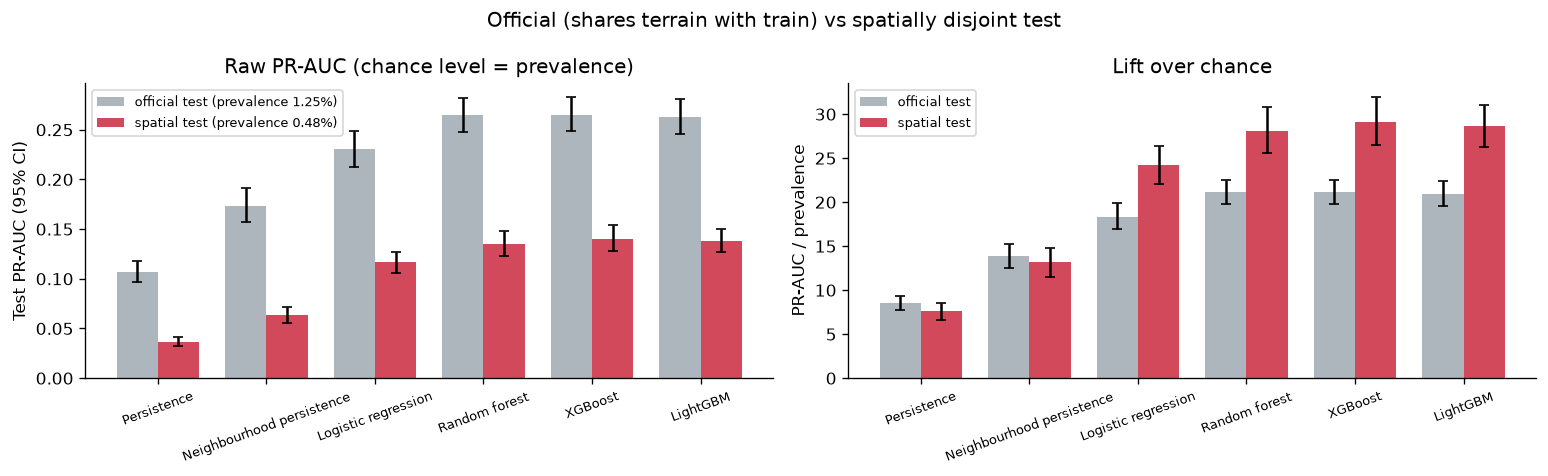

In [6]:
display(Image(f'{R}/protocol_gap.png'))

## 4. Model selection and hyperparameters (validation split)

In [7]:
sel = json.load(open(f'{R}/spatial/results.json'))['selection']
for k, v in sel.items():
    print(k, json.dumps(v, indent=1)[:600])

logistic_regression [
 {
  "importance_weighted": false,
  "val_pr_auc": 0.17105690702248003,
  "fit_seconds": 13.835230112075806
 },
 {
  "importance_weighted": true,
  "val_pr_auc": 0.18770914894088123,
  "fit_seconds": 15.496711015701294
 }
]
logistic_regression_best {
 "importance_weighted": true
}
random_forest [
 {
  "importance_weighted": false,
  "val_pr_auc": 0.2269287469942542,
  "fit_seconds": 99.6639358997345
 },
 {
  "importance_weighted": true,
  "val_pr_auc": 0.228017971720424,
  "fit_seconds": 75.41257905960083
 }
]
random_forest_best {
 "importance_weighted": true
}
xgboost [
 {
  "params": {
   "max_depth": 6,
   "min_child_weight": 100
  },
  "val_pr_auc": 0.2289023448740601,
  "n_trees": 88,
  "fit_seconds": 19.134902954101562
 },
 {
  "params": {
   "max_depth": 8,
   "min_child_weight": 1000
  },
  "val_pr_auc": 0.23040778553039293,
  "n_trees": 241,
  "fit_seconds": 31.02343988418579
 }
]
xgboost_best {
 "params": {
  "max_depth": 8,
  "min_child_weight": 1000
 }

## 5. Feature-group ablation (LightGBM, spatial split)

,n_features,val_pr_auc,test_pr_auc
raw_only,10,0.0247,0.0097
fire_only,8,0.1911,0.1107
raw+fire,18,0.2122,0.1298
raw+fire+wind,24,0.2257,0.1398
raw+fire+wind+terrain,28,0.2276,0.1425
all_features,32,0.2297,0.1381
all_minus_raw,22,0.2261,0.1385
all_minus_fire,24,0.2126,0.1305
all_minus_wind,26,0.2196,0.1394
all_minus_terrain,28,0.2270,0.1388


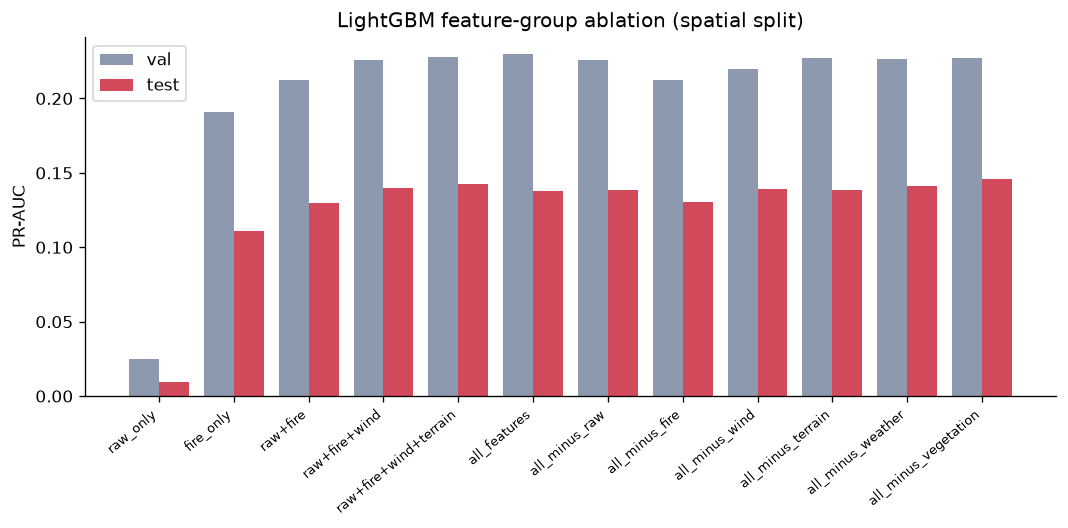

In [8]:
ab = json.load(open(f'{R}/spatial/results.json'))['ablation']
display(pd.DataFrame(ab).T[['n_features','val_pr_auc','test_pr_auc']])
display(Image(f'{R}/spatial/ablation.png'))

## 6. Interpretation: feature importance and SHAP

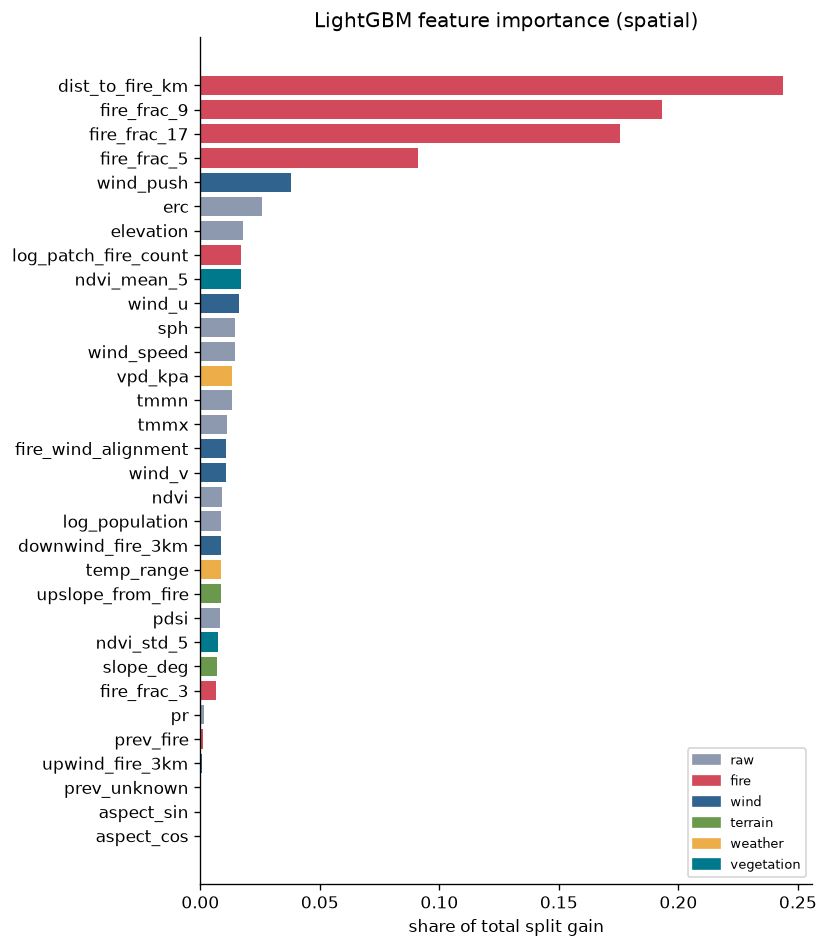

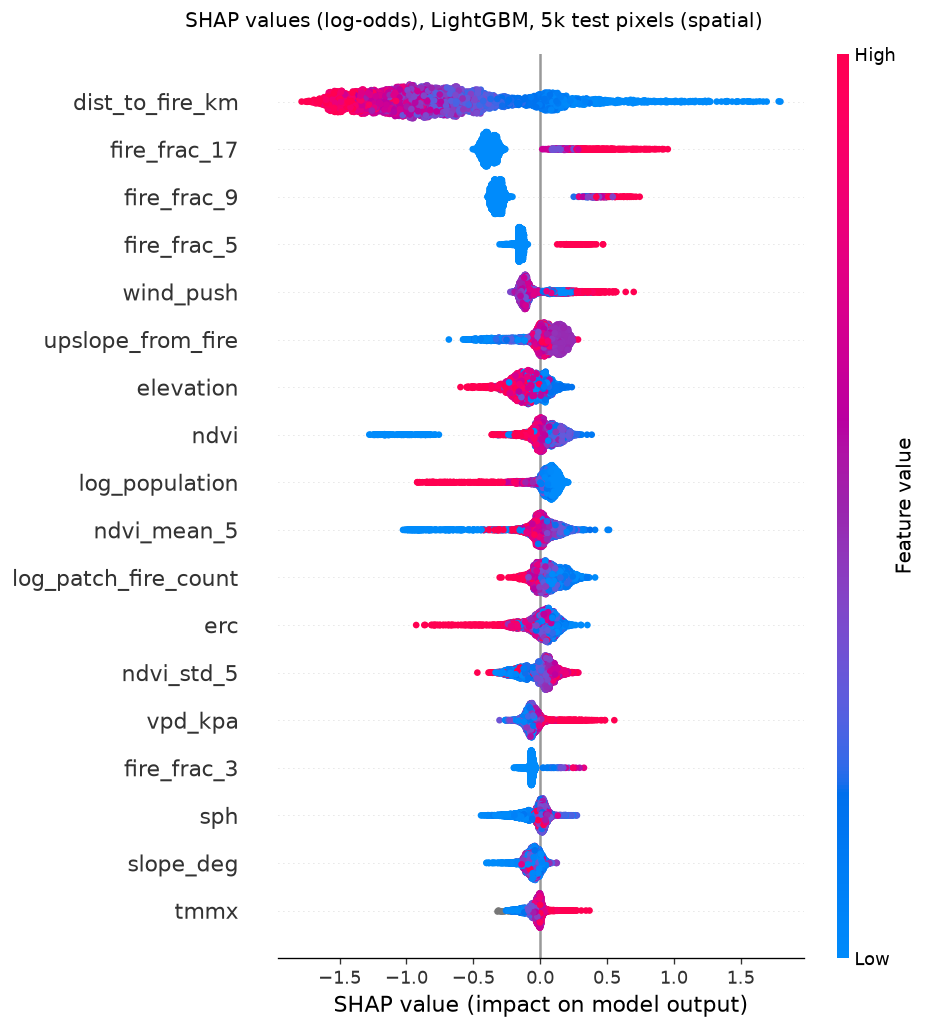

In [9]:
display(Image(f'{R}/spatial/feature_importance.png')); display(Image(f'{R}/spatial/shap_summary.png'))

## 7. Calibration

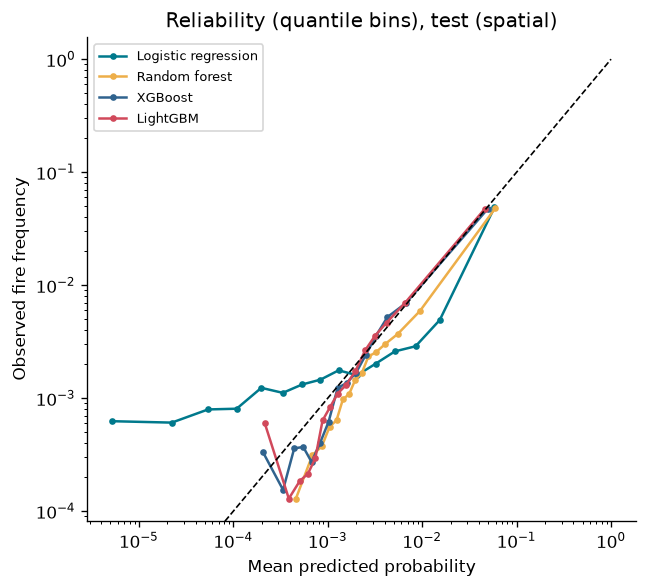

In [10]:
display(Image(f'{R}/spatial/calibration.png'))

## 8. Probability maps and physical plausibility

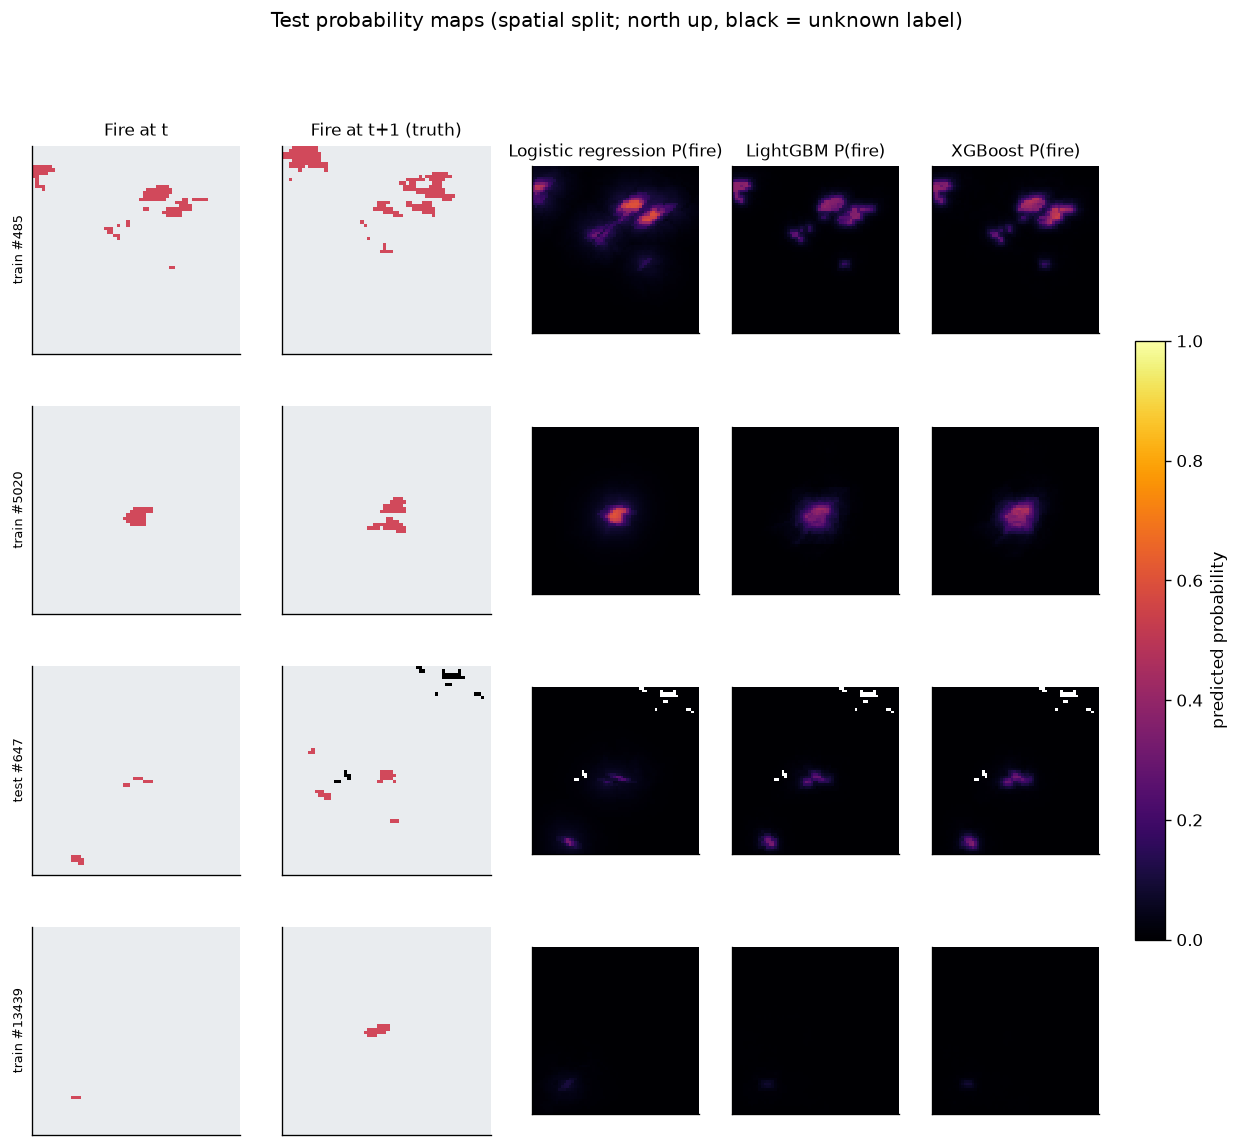

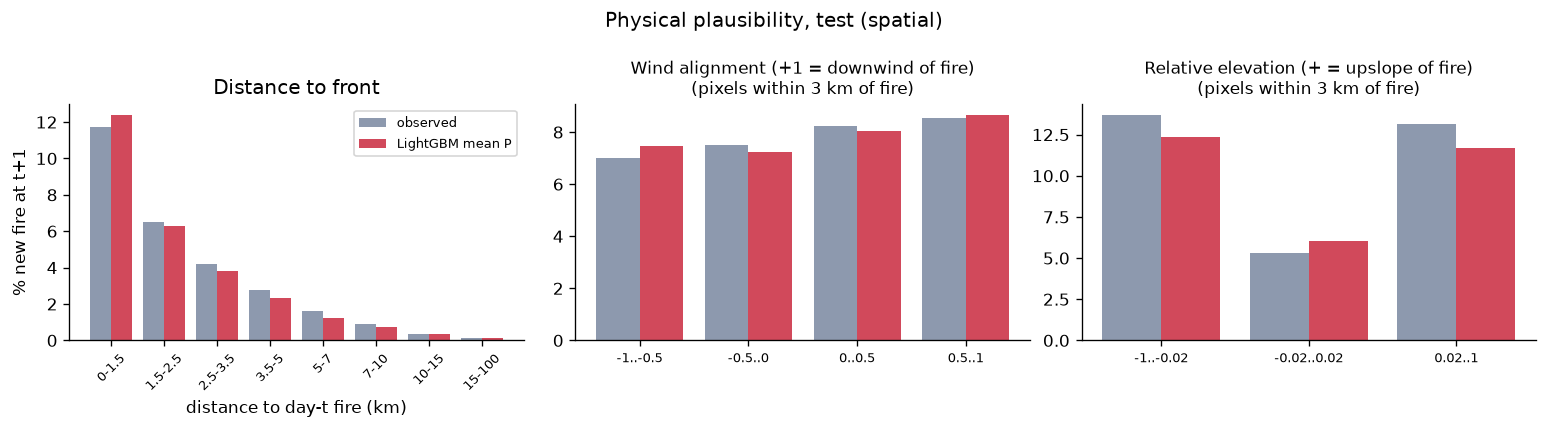

,observed,predicted
0-1.5,0.1171,0.1237
1.5-2.5,0.0650,0.0630
2.5-3.5,0.0421,0.0382
3.5-5,0.0279,0.0233
5-7,0.0163,0.0122
7-10,0.0088,0.0074
10-15,0.0038,0.0038
15-100,0.0012,0.0014


In [11]:
display(Image(f'{R}/spatial/probability_maps.png')); display(Image(f'{R}/spatial/plausibility.png'))
pd.DataFrame(json.load(open(f'{R}/spatial/interpretation.json'))['plausibility']['distance_km']).T